<a href="https://colab.research.google.com/github/fmezacr/DataScienceTEC/blob/master/ML_Titanic_EDA_Preprocesamiento.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

---

<div style="font-size:small;">

MIT License

Copyright (c) [2026] Felipe Meza-Obando

*Permission is hereby granted, free of charge, to any person obtaining a copy
of this software and associated documentation files (the "Software"), to deal
in the Software for educational purposes only. You must give author appropriate credit, provide a link to the license and source, and indicate if changes were made.*
</div>

---

# Del dato al modelo: EDA y preprocesamiento con Titanic
**Curso:** Machine Learning aplicado a Ciencia de Datos  
**Objetivo:** comprender cómo las observaciones sobre los datos determinan qué se conserva, corrige, transforma y modela.

**Problema:** predecir `Survived` (1 = sobrevivió; 0 = no sobrevivió) a partir de información registrada sobre pasajeros del Titanic. Ejercicio académico con un dataset histórico; sus relaciones no deben interpretarse como causales.

**Ruta:** 1. Carga y partición → 2. EDA → 3. Decisiones de preprocesamiento → 4. Benchmark → 5. Validación y evaluación → 6. Conclusiones.  
**Regla:** el conjunto de prueba se reserva hasta el final. El EDA que guía decisiones utiliza exclusivamente entrenamiento.

## 1. Carga, revisión inicial y partición
**¿Qué hacemos?** Cargamos registros, revisamos su estructura y separamos una muestra que no usaremos para decidir transformaciones.  
**¿Por qué?** Una revisión de calidad precede al modelado; examinar el conjunto de prueba para elegir decisiones sesgaría la evaluación.  
**¿Qué indican los resultados?** Los recuentos y tipos de datos orientan el EDA siguiente.

**Variables:** `Pclass` (clase), `Sex`, `Age`, `SibSp` (hermanos/cónyuges a bordo), `Parch` (padres/hijos), `Fare` (tarifa), `Embarked` (puerto); también hay identificadores, texto libre y cabina. La variable objetivo es `Survived`.

Fuente: [Titanic CSV — Data Science Dojo, GitHub](https://github.com/datasciencedojo/datasets/blob/master/titanic.csv). El código requiere internet la primera vez.

In [14]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, ConfusionMatrixDisplay)

SEED = 42
URL = "https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv"
df = pd.read_csv(URL)
assert {'Survived','Pclass','Sex','Age','SibSp','Parch','Fare','Embarked'}.issubset(df.columns)
print(f"Registros: {len(df)} | Columnas: {df.shape[1]}")
display(df.head())
display(df.dtypes.rename('Tipo').to_frame())

Registros: 891 | Columnas: 12


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


,Tipo
PassengerId,int64
Survived,int64
Pclass,int64
Name,object
Sex,object
Age,float64
SibSp,int64
Parch,int64
Ticket,object
Fare,float64


**Decisión de partición.** Conservamos un 20 % para prueba con muestreo estratificado, de modo que ambas particiones mantengan aproximadamente la proporción de supervivientes. No se imputan valores antes de dividir.

In [15]:
# La inspección de duplicados se hace sobre registros completos, no solo sobre variables repetidas.
print("Filas idénticas:", df.duplicated().sum())
print("Identificadores repetidos:", df['PassengerId'].duplicated().sum())

train, test = train_test_split(df, test_size=0.20, stratify=df['Survived'],
                               random_state=SEED)
train = train.copy(); test = test.copy()
print(f"Entrenamiento: {len(train)} | Prueba reservada: {len(test)}")
print("Supervivencia en entrenamiento:", round(train['Survived'].mean(), 3))

Filas idénticas: 0
Identificadores repetidos: 0
Entrenamiento: 712 | Prueba reservada: 179
Supervivencia en entrenamiento: 0.383


## 2. EDA: observar antes de transformar
**¿Qué hacemos?** Exploramos **únicamente entrenamiento**, con pocas gráficas que respondan preguntas concretas.  
**¿Por qué?** El EDA permite justificar el manejo de faltantes, categorías y variables.  
**¿Qué indican los resultados?** Cada celda imprime una lectura calculada; las asociaciones descriptivas no demuestran causalidad.

### 2.1 ¿Hay faltantes, tipos incorrectos o valores sospechosos?
El porcentaje de faltantes permite decidir entre descartar una columna o imputarla. Las estadísticas y los rangos ayudan a detectar errores plausibles.

In [16]:
calidad = pd.DataFrame({
    'tipo': train.dtypes.astype(str),
    'faltantes': train.isna().sum(),
    '% faltantes': (100 * train.isna().mean()).round(1),
    'valores únicos': train.nunique(dropna=True)
}).sort_values('% faltantes', ascending=False)
display(calidad)
display(train[['Age','Fare','SibSp','Parch']].describe().round(2))
print("Edades fuera de [0, 110]:", ((train['Age'] < 0) | (train['Age'] > 110)).sum())
print("Tarifas negativas:", (train['Fare'] < 0).sum())
print("Clases registradas:", sorted(train['Pclass'].dropna().unique().tolist()))
print("Puertos registrados:", train['Embarked'].value_counts(dropna=False).to_dict())

,tipo,faltantes,% faltantes,valores únicos
Cabin,object,552,77.5,127
Age,float64,137,19.2,85
Embarked,object,2,0.3,3
PassengerId,int64,0,0.0,712
Name,object,0,0.0,712
Pclass,int64,0,0.0,3
Survived,int64,0,0.0,2
Sex,object,0,0.0,2
Parch,int64,0,0.0,7
SibSp,int64,0,0.0,7


,Age,Fare,SibSp,Parch
count,575.00,712.00,712.00,712.00
mean,29.81,31.82,0.49,0.39
std,14.49,48.06,1.06,0.84
min,0.42,0.00,0.00,0.00
25%,21.00,7.90,0.00,0.00
50%,28.50,14.45,0.00,0.00
75%,39.00,31.00,1.00,0.00
max,80.00,512.33,8.00,6.00


Edades fuera de [0, 110]: 0
Tarifas negativas: 0
Clases registradas: [1, 2, 3]
Puertos registrados: {'S': 516, 'C': 139, 'Q': 55, nan: 2}


### 2.2 ¿La variable objetivo está desbalanceada?
Un predominio de una clase hace insuficiente evaluar solo *accuracy*.

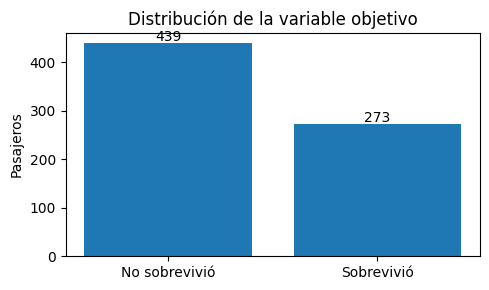

Clase mayoritaria: 0 (61.7% del entrenamiento).


In [17]:
cuentas = train['Survived'].value_counts().reindex([0,1], fill_value=0)
fig, ax = plt.subplots(figsize=(5,3))
ax.bar(['No sobrevivió','Sobrevivió'], cuentas.values)
ax.set(ylabel='Pasajeros', title='Distribución de la variable objetivo')
for i, v in enumerate(cuentas.values): ax.text(i, v + 5, str(v), ha='center')
plt.tight_layout(); plt.show()
print(f"Clase mayoritaria: {cuentas.idxmax()} ({cuentas.max()/cuentas.sum():.1%} del entrenamiento).")

### 2.3 ¿Qué variables categóricas muestran diferencias de supervivencia?
Usamos **tasas** dentro de cada grupo, no recuentos absolutos, para comparar grupos de distinto tamaño.

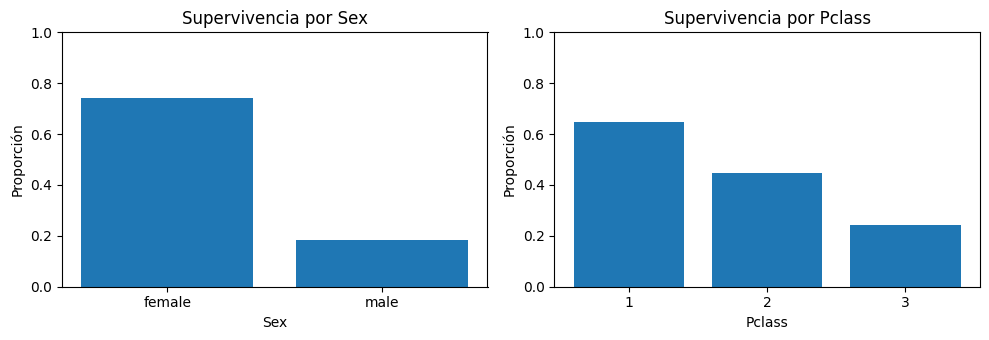

Sex: tasas de supervivencia por grupo


,n,tasa
Sex,,
female,253,0.743
male,459,0.185


Pclass: tasas de supervivencia por grupo


,n,tasa
Pclass,,
1,171,0.649
2,150,0.447
3,391,0.243


Lectura: las diferencias visualizadas son asociaciones descriptivas, no efectos causales.


In [18]:
fig, axes = plt.subplots(1,2,figsize=(10,3.5))
for ax, col, orden in zip(axes, ['Sex','Pclass'], [['female','male'],[1,2,3]]):
    tasas = train.groupby(col)['Survived'].mean().reindex(orden)
    ax.bar(tasas.index.astype(str), tasas.values)
    ax.set(title=f'Supervivencia por {col}', xlabel=col, ylabel='Proporción', ylim=(0,1))
plt.tight_layout(); plt.show()
for col in ['Sex','Pclass']:
    print(f"{col}: tasas de supervivencia por grupo")
    display(train.groupby(col)['Survived'].agg(n='size', tasa='mean').round(3))
print('Lectura: las diferencias visualizadas son asociaciones descriptivas, no efectos causales.')

### 2.4 ¿Cómo se distribuyen edad y tarifa, y qué relación tienen con la supervivencia?
Las distribuciones permiten observar dispersión y asimetría. No eliminaremos valores extremos solo por ser grandes: una tarifa elevada puede ser legítima.

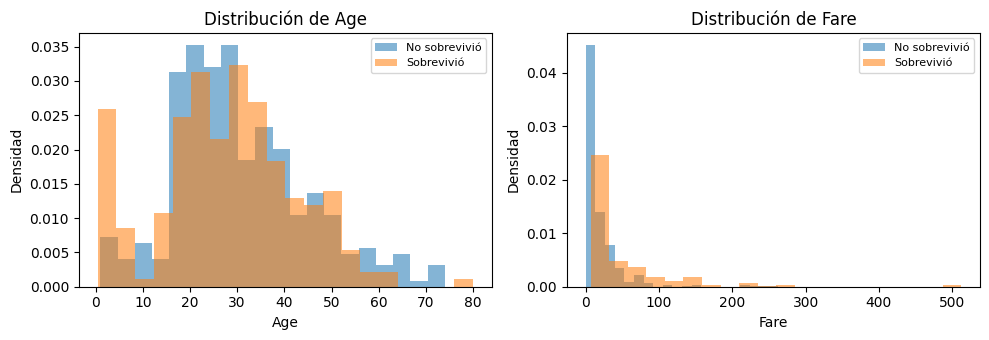

Medianas por clase (sin imputar):


,Age,Fare
Survived,,
0,28.25,10.5
1,29.00,26.0


Proporción de tarifas mayores que 100: 6.0%


In [19]:
fig, axes = plt.subplots(1,2,figsize=(10,3.5))
for ax, col in zip(axes, ['Age','Fare']):
    for estado, nombre in [(0,'No sobrevivió'),(1,'Sobrevivió')]:
        valores = train.loc[train['Survived']==estado, col].dropna()
        ax.hist(valores, bins=20, alpha=.55, density=True, label=nombre)
    ax.set(title=f'Distribución de {col}', xlabel=col, ylabel='Densidad')
    ax.legend(fontsize=8)
plt.tight_layout(); plt.show()
print('Medianas por clase (sin imputar):')
display(train.groupby('Survived')[['Age','Fare']].median().round(2))
print('Proporción de tarifas mayores que 100:', f"{(train['Fare'] > 100).mean():.1%}")

### 2.5 ¿Hay información aprovechable en la composición familiar?
`SibSp` y `Parch` son recuentos relacionados. Para simplificar la explicación, construiremos `FamilySize = SibSp + Parch + 1` y retiraremos las dos originales, evitando usar versiones redundantes en este ejercicio.

,n,tasa
FamilySize,,
1,434,0.300
2,129,0.550
3,77,0.623
4,22,0.727
5,14,0.214
6,16,0.062
7,11,0.364
8,4,0.000
11,5,0.000


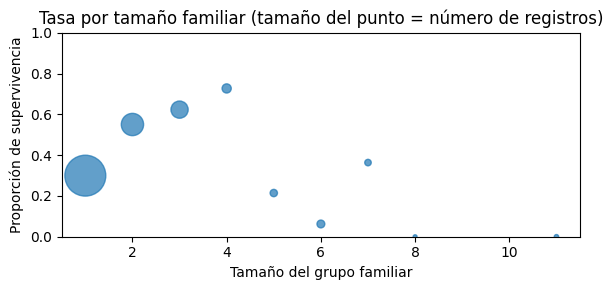

Advertencia: grupos con pocos registros producen tasas inestables.


In [20]:
eda_familia = train.assign(FamilySize=train['SibSp'] + train['Parch'] + 1)
resumen_familia = eda_familia.groupby('FamilySize')['Survived'].agg(n='size', tasa='mean')
display(resumen_familia.round(3))
fig, ax = plt.subplots(figsize=(6,3))
ax.scatter(resumen_familia.index, resumen_familia['tasa'], s=resumen_familia['n']*2, alpha=.7)
ax.set(xlabel='Tamaño del grupo familiar', ylabel='Proporción de supervivencia',
       title='Tasa por tamaño familiar (tamaño del punto = número de registros)', ylim=(0,1))
plt.tight_layout(); plt.show()
print('Advertencia: grupos con pocos registros producen tasas inestables.')

## 3. Preprocesamiento: justificar cada decisión
**¿Qué hacemos?** Convertimos el EDA en una política explícita: conservar, descartar, crear, imputar, codificar o escalar.  
**¿Por qué?** No toda columna aporta una característica interpretable; no toda transformación es necesaria.  
**¿Qué indican los resultados?** Comprobaremos que la matriz de entrenamiento es completamente numérica y carece de faltantes, sin tocar la prueba para estimar transformaciones.

| Elemento | Decisión | Justificación didáctica |
|---|---|---|
| `PassengerId` | Descartar | Identificador, no atributo sustantivo. |
| `Name`, `Ticket` | Descartar | Texto de alta cardinalidad; procesarlo exigiría técnicas fuera del alcance. No afirmamos que carezca de información. |
| `Cabin` | Descartar | Alto porcentaje de faltantes, evidente en la tabla de calidad. |
| `SibSp`, `Parch` | Combinar en `FamilySize` | Resumir información familiar en una característica fácil de interpretar. |
| `Age`, `Fare`, `FamilySize` | Conservar como numéricas | Información interpretable; la **mediana** resiste valores extremos. |
| `Sex`, `Embarked`, `Pclass` | Tratar como categorías | `Pclass` es un código de categoría, no una magnitud física. Usamos one-hot. |
| Categorías faltantes | Imputar moda | No eliminamos pasajeros por unos pocos registros sin puerto de embarque. |
| Escalado | Solo regresión logística | Igualar escalas ayuda al modelo lineal regularizado; el árbol no lo necesita. |

**Importante:** el umbral para descartar `Cabin` se basa en su ausencia y en la simplicidad docente, no en demostrar que la columna es irrelevante. La imputación, codificación y estandarización se **ajustan en entrenamiento dentro de cada fold** mediante `Pipeline`.

In [21]:
# Función determinista: NO calcula medias, medianas ni estadísticas globales.
def preparar_columnas(datos):
    X = datos.copy()
    X['FamilySize'] = X['SibSp'] + X['Parch'] + 1
    return X[['Age','Fare','FamilySize','Sex','Embarked','Pclass']]

X_train = preparar_columnas(train)
y_train = train['Survived']
X_test = preparar_columnas(test)   # Solo estructura; no se inspeccionan resultados de prueba.
y_test = test['Survived']

numericas = ['Age','Fare','FamilySize']
categoricas = ['Sex','Embarked','Pclass']

def crear_preprocesador(escalar):
    pasos_num = [('imputar', SimpleImputer(strategy='median'))]
    if escalar:
        pasos_num.append(('escalar', StandardScaler()))
    return ColumnTransformer([
        ('numericas', Pipeline(pasos_num), numericas),
        ('categoricas', Pipeline([
            ('imputar', SimpleImputer(strategy='most_frequent')),
            ('codificar', OneHotEncoder(handle_unknown='ignore'))
        ]), categoricas)
    ])

print('Características que ingresan a los modelos:')
display(X_train.head())
print('Faltantes ANTES de la imputación:', X_train.isna().sum().to_dict())

Características que ingresan a los modelos:


,Age,Fare,FamilySize,Sex,Embarked,Pclass
692,NaN,56.4958,1,male,S,3
481,NaN,0.0000,1,male,S,2
527,NaN,221.7792,1,male,S,1
855,18.0,9.3500,2,female,S,3
801,31.0,26.2500,3,female,S,2


Faltantes ANTES de la imputación: {'Age': 137, 'Fare': 0, 'FamilySize': 0, 'Sex': 0, 'Embarked': 2, 'Pclass': 0}


### 3.1 Verificar la transformación sin filtraciones
La siguiente demostración ajusta **una copia** del preprocesador exclusivamente en entrenamiento. Los modelos volverán a ajustarlo dentro de sus pipelines y de la validación cruzada.

In [22]:
pre_demo = crear_preprocesador(escalar=True)
transformado = pre_demo.fit_transform(X_train)
nombres = pre_demo.get_feature_names_out()
print('Variables originales:', X_train.shape[1], '| Columnas resultantes:', len(nombres))
print('Faltantes después:', np.isnan(transformado).sum())
display(pd.DataFrame(transformado[:5], columns=nombres).round(2))
print('Medianas aprendidas solo en entrenamiento:',
      dict(zip(numericas, pre_demo.named_transformers_['numericas'].named_steps['imputar'].statistics_)))

Variables originales: 6 | Columnas resultantes: 11
Faltantes después: 0


,numericas__Age,numericas__Fare,numericas__FamilySize,categoricas__Sex_female,categoricas__Sex_male,categoricas__Embarked_C,categoricas__Embarked_Q,categoricas__Embarked_S,categoricas__Pclass_1,categoricas__Pclass_2,categoricas__Pclass_3
0,-0.08,0.51,-0.56,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0
1,-0.08,-0.66,-0.56,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0
2,-0.08,3.96,-0.56,0.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0
3,-0.89,-0.47,0.07,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0
4,0.11,-0.12,0.70,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0


Medianas aprendidas solo en entrenamiento: {'Age': np.float64(28.5), 'Fare': np.float64(14.4542), 'FamilySize': np.float64(1.0)}


## 4. Benchmark: dos modelos, misma información
**¿Qué hacemos?** Comparamos regresión logística regularizada y árbol de decisión de profundidad limitada.  
**¿Por qué?** La regresión logística ofrece una referencia lineal interpretable; el árbol modela divisiones no lineales y puede sobreajustarse si crece sin control.  
**¿Qué indican los resultados?** La validación cruzada medirá capacidad predictiva sobre particiones no vistas durante cada ajuste.

Ambos usan las mismas seis características y los mismos cinco folds estratificados. El árbol tiene `max_depth=4` para limitar su complejidad, sin búsqueda extensa de hiperparámetros.

In [23]:
modelos = {
    'Regresión logística': Pipeline([
        ('preprocesar', crear_preprocesador(escalar=True)),
        ('modelo', LogisticRegression(max_iter=1000, random_state=SEED))
    ]),
    'Árbol de decisión': Pipeline([
        ('preprocesar', crear_preprocesador(escalar=False)),
        ('modelo', DecisionTreeClassifier(max_depth=4, min_samples_leaf=10,
                                         random_state=SEED))
    ])
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
metricas = {'accuracy':'accuracy', 'precision':'precision',
            'recall':'recall', 'f1':'f1'}
filas=[]
for nombre, modelo in modelos.items():
    scores = cross_validate(modelo, X_train, y_train, cv=cv, scoring=metricas,
                            return_train_score=True)
    fila={'Modelo':nombre}
    for metrica in metricas:
        fila[f'{metrica} CV'] = scores[f'test_{metrica}'].mean()
        fila[f'{metrica} DE'] = scores[f'test_{metrica}'].std()
    fila['F1 entrenamiento'] = scores['train_f1'].mean()
    fila['Brecha F1'] = fila['F1 entrenamiento'] - fila['f1 CV']
    filas.append(fila)
comparacion_cv = pd.DataFrame(filas).set_index('Modelo')
display(comparacion_cv.round(3))

,accuracy CV,accuracy DE,precision CV,precision DE,recall CV,recall DE,f1 CV,f1 DE,F1 entrenamiento,Brecha F1
Modelo,,,,,,,,,,
Regresión logística,0.802,0.014,0.768,0.029,0.696,0.037,0.729,0.021,0.737,0.008
Árbol de decisión,0.813,0.015,0.827,0.036,0.652,0.053,0.727,0.029,0.760,0.033


## 5. Sobreajuste, selección y evaluación final
**¿Qué hacemos?** Comparamos F1 dentro y fuera de cada fold; después seleccionamos por **F1 medio de CV** y realizamos una evaluación final en el conjunto de prueba.  
**¿Por qué?** Un entrenamiento muy superior a la validación sugiere sobreajuste; la prueba no se usa para escoger el modelo.  
**¿Qué indican los resultados?** La brecha y la variabilidad entre folds son indicios, no pruebas definitivas, de generalización.

**Métricas:** accuracy = fracción de aciertos; precision = proporción de supervivientes correctos entre los predichos como supervivientes; recall = proporción de supervivientes identificados; F1 = media armónica de precision y recall. La clase positiva es `Survived=1`. Elegimos F1 para equilibrar ambos tipos de error en el ejercicio; otra aplicación podría priorizar recall.

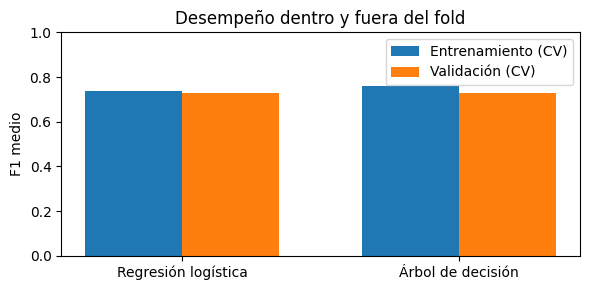

Regresión logística: brecha F1 = +0.008; desviación F1 CV = 0.021.
Árbol de decisión: brecha F1 = +0.033; desviación F1 CV = 0.029.


In [24]:
fig, ax = plt.subplots(figsize=(6,3))
nombres_modelo = comparacion_cv.index.tolist()
x = np.arange(len(nombres_modelo)); w = .35
ax.bar(x-w/2, comparacion_cv['F1 entrenamiento'], w, label='Entrenamiento (CV)')
ax.bar(x+w/2, comparacion_cv['f1 CV'], w, label='Validación (CV)')
ax.set(xticks=x, xticklabels=nombres_modelo, ylabel='F1 medio', ylim=(0,1),
       title='Desempeño dentro y fuera del fold')
ax.legend(); plt.tight_layout(); plt.show()
for nombre, fila in comparacion_cv.iterrows():
    print(f"{nombre}: brecha F1 = {fila['Brecha F1']:+.3f}; desviación F1 CV = {fila['f1 DE']:.3f}.")

### Selección antes de abrir la prueba
Se escoge el mayor F1 promedio de validación cruzada. A continuación se ajusta **solo el elegido** con todo entrenamiento y se evalúa una única vez sobre prueba. Las métricas de CV para ambos modelos ya permiten compararlos sin utilizar prueba para tomar decisiones.

Modelo seleccionado antes de la prueba: Regresión logística


,accuracy CV,precision CV,recall CV,f1 CV,Brecha F1,Modelo seleccionado
Modelo,,,,,,
Regresión logística,0.802,0.768,0.696,0.729,0.008,True
Árbol de decisión,0.813,0.827,0.652,0.727,0.033,False


,Prueba final
Accuracy,0.799
Precision,0.780
Recall,0.667
F1,0.719


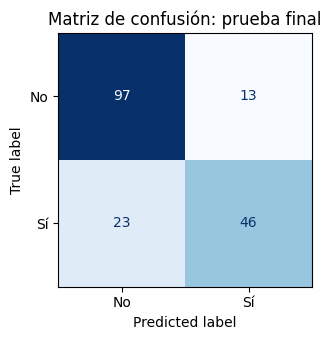

In [25]:
elegido = comparacion_cv['f1 CV'].idxmax()
modelo_final = modelos[elegido]
modelo_final.fit(X_train, y_train)
pred = modelo_final.predict(X_test)
resultado_prueba = pd.Series({
    'Accuracy':accuracy_score(y_test,pred),
    'Precision':precision_score(y_test,pred,zero_division=0),
    'Recall':recall_score(y_test,pred,zero_division=0),
    'F1':f1_score(y_test,pred,zero_division=0)
}, name='Prueba final')
print('Modelo seleccionado antes de la prueba:', elegido)
display(pd.concat([comparacion_cv[['accuracy CV','precision CV','recall CV','f1 CV','Brecha F1']].round(3),
                   pd.DataFrame({'Modelo seleccionado':[nombre==elegido for nombre in comparacion_cv.index]}, index=comparacion_cv.index)],axis=1))
display(resultado_prueba.to_frame().round(3))
fig, ax = plt.subplots(figsize=(4,3.5))
ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=['No','Sí'],
                                        cmap='Blues', colorbar=False, ax=ax)
ax.set_title('Matriz de confusión: prueba final')
plt.tight_layout(); plt.show()

## 6. Resultados y conclusiones a partir de la ejecución
**¿Qué hacemos?** Respondemos las preguntas del proceso con cálculos, sin anticipar cifras.  
**¿Por qué?** La conclusión debe derivarse de evidencia, no de una afirmación preparada de antemano.  
**¿Qué indican los resultados?** El siguiente resumen se construye usando las métricas reales.

In [26]:
ganador_cv = comparacion_cv['f1 CV'].idxmax()
fila = comparacion_cv.loc[ganador_cv]
print(f"1. Mayor F1 medio en validación: {ganador_cv} ({fila['f1 CV']:.3f}).")
print(f"2. Evidencia de generalización: F1 entrenamiento={fila['F1 entrenamiento']:.3f}; "
      f"F1 CV={fila['f1 CV']:.3f}; brecha={fila['Brecha F1']:+.3f}; "
      f"desviación entre folds={fila['f1 DE']:.3f}; F1 prueba={resultado_prueba['F1']:.3f}.")
print(f"3. Métrica principal: F1. En prueba, precision={resultado_prueba['Precision']:.3f} "
      f"y recall={resultado_prueba['Recall']:.3f}; su importancia relativa depende del costo de los errores.")
print('4. Limitaciones: muestra histórica pequeña; asociaciones no causales; '
      'los datos no representan una población moderna; selección y configuración simples; '
      'la estimación final en una sola partición tiene incertidumbre.')

1. Mayor F1 medio en validación: Regresión logística (0.729).
2. Evidencia de generalización: F1 entrenamiento=0.737; F1 CV=0.729; brecha=+0.008; desviación entre folds=0.021; F1 prueba=0.719.
3. Métrica principal: F1. En prueba, precision=0.780 y recall=0.667; su importancia relativa depende del costo de los errores.
4. Limitaciones: muestra histórica pequeña; asociaciones no causales; los datos no representan una población moderna; selección y configuración simples; la estimación final en una sola partición tiene incertidumbre.
